In [1]:
import torch
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import graph_utils as gu


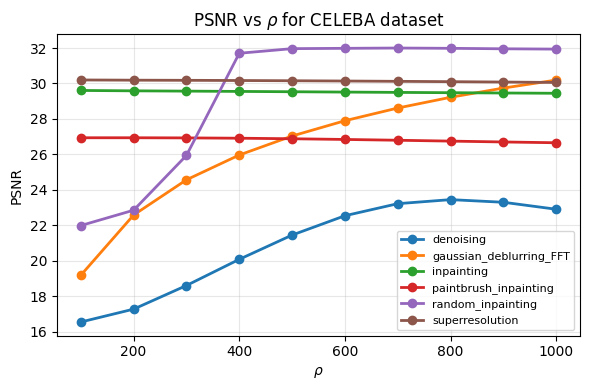

Saved: results/celeba_admm_rho_graph/ot/psnr_vs_rho_admm.png


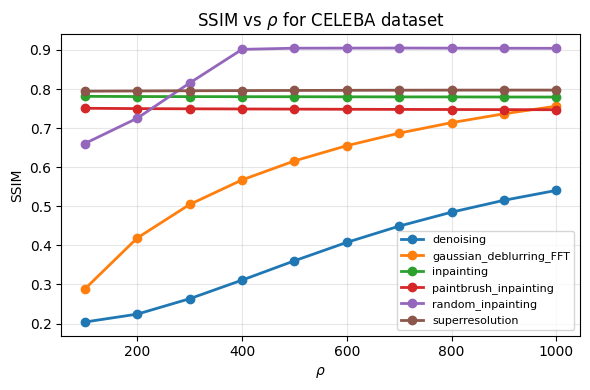

Saved: results/celeba_admm_rho_graph/ot/ssim_vs_rho_admm.png


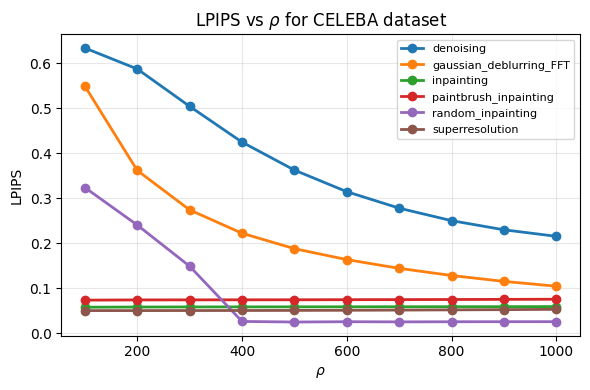

Saved: results/celeba_admm_rho_graph/ot/lpips_vs_rho_admm.png


In [2]:
BASE_DIR = Path("results/celeba_admm_rho_graph/ot")
METHODS = [
    "denoising",
    "gaussian_deblurring_FFT",
    "inpainting",
    "paintbrush_inpainting",
    "random_inpainting",
    "superresolution",
]
METRIC_CONFIG = {
    "final_psnr.txt":  ("psnr_rec", "PSNR"),
    "final_ssim.txt":  ("ssim_rec", "SSIM"),
    "final_lpips.txt": ("lpips_rec", "LPIPS"),   
}

for metric_file, (y_col, ylabel) in METRIC_CONFIG.items():
    save_name = f"{ylabel.lower()}_vs_rho_admm.png"
    gu.plot_all_methods(
        base_dir=BASE_DIR,
        methods=METHODS,
        metric_file=metric_file,
        y_col=y_col,
        ylabel=ylabel,
        save_name=save_name
    )


## Ablations

In [2]:
ROOT_DIR = Path("results/afhq_cat/ot")
OUT_CSV = "ablation_summary.csv"
OUT_XLSX = "ablation_summary.xlsx"

# Methods you care about
METHODS = {
    "pnp_flow_admm": "adaptive_noise",
    "pnp_flow_fbs": "random_noise",
}

METRIC_FILES = {
    "psnr": "final_psnr.txt",
    "ssim": "final_ssim.txt",
    "lpips": "final_lpips.txt",
}

df = gu.collect_results(METHODS, METRIC_FILES, ROOT_DIR)
if df.empty:
    print("No matching results found.")
else:
    gu.save_outputs(df, OUT_CSV, OUT_XLSX)
    print(f"Saved CSV  : {OUT_CSV}")
    print(f"Saved Excel: {OUT_XLSX}")
    print("\nPreview:")

Saved CSV  : ablation_summary.csv
Saved Excel: ablation_summary.xlsx

Preview:


## Results on single image for comparison

In [ ]:
ROOT_DIR = Path("results/afhq_cat_single_image_paper/ot")

df = gu.extract_basic_metrics(ROOT_DIR, "single_image_metrics.xlsx")
# display(df)

In [2]:
ROOT_DIR = Path("results/celeba/ot")
df = gu.extract_basic_metrics(ROOT_DIR, "celeba_100.xlsx")
display(df)

,task,method,ssim_rec,ssim_noisy,lpips_rec,lpips_noisy,psnr_rec,psnr_noisy
0,denoising,pnp_flow_admm,0.5997,0.2441,0.1742,0.5585,21.5517,16.4799
1,gaussian_deblurring_FFT,pnp_flow_admm,0.7953,0.7451,0.0878,0.1215,30.5589,27.8648
2,inpainting,pnp_flow_admm,0.7963,0.7461,0.0429,0.2026,28.2034,22.3317
3,paintbrush_inpainting,pnp_flow_admm,0.7460,0.6603,0.0812,0.2991,25.2997,18.8544
4,random_inpainting,pnp_flow_admm,0.9019,0.2007,0.0204,1.0218,30.9011,12.2518
5,superresolution,pnp_flow_admm,0.7920,0.1793,0.0476,0.8262,28.8654,10.2651
